<a href="https://colab.research.google.com/github/jatinkumar-creator/machine-learning-portfolio/blob/main/06_Ensemble_Learning/notebooks/04_Model_Selection_and_Hyperparameter_Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model Selection and Hyperparameter Optimization

## Objectives
- Understand model selection.
- Understand parameters and hyperparameters.
- Learn cross-validation strategies.
- Implement GridSearchCV.
- Implement RandomizedSearchCV.
- Compare model configurations.
- Evaluate the final selected model.

## Dataset
Wine Classification Dataset

## Algorithms
- Random Forest
- Decision Tree
- Logistic Regression

## Optimization Techniques
- GridSearchCV
- RandomizedSearchCV

## Evaluation
- Accuracy
- Precision
- Recall
- F1-score
- Cross-validation
- Confusion Matrix

In [1]:
#Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import randint

from sklearn.datasets import load_wine

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
#Load the Wine dataset
wine = load_wine()

X = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

y = pd.Series(wine.target, name="wine_class")

print("Features:", X.shape)
print("Target:", y.shape)

print("\nClass distribution:")
print(y.value_counts().sort_index())

Features: (178, 13)
Target: (178,)

Class distribution:
wine_class
0    59
1    71
2    48
Name: count, dtype: int64


In [3]:
#Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 142
Testing records: 36


StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
Fold scores: [0.93103448 1.         1.         1.         0.96428571]
Mean accuracy: 0.9790640394088669
Standard deviation: 0.027713464392187602
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best parameters:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

Best CV accuracy:
0.9790640394088669
Optimized model:
RandomForestClassifier(random_state=42)
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best parameters:
{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'min_samples_split': 9, 'n_estimators': 238}

Best CV accuracy:
0.9790640394088669
RandomForestClassifier(max_depth=10, min_samples_leaf=3, min_samples_split=9,
                       n_estimators=238, random_state=42)


,Search Method,Best CV Accuracy
0,GridSearchCV,0.979064
1,RandomizedSearchCV,0.979064


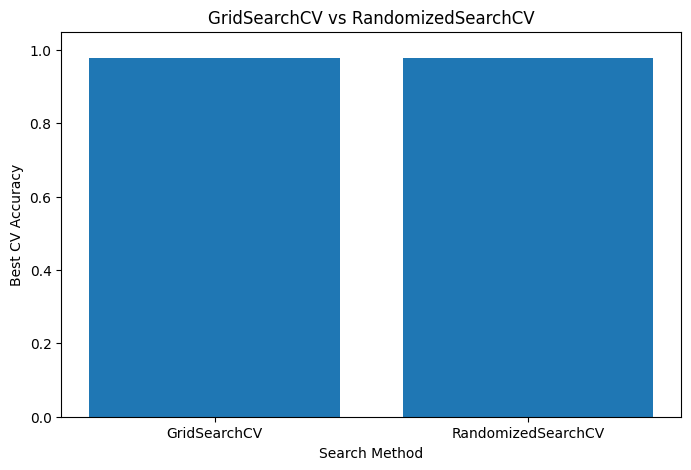

,Model,Accuracy,Precision,Recall,F1 Score
0,Baseline Random Forest,1.0,1.0,1.0,1.0
1,GridSearchCV Random Forest,1.0,1.0,1.0,1.0
2,RandomizedSearchCV Random Forest,1.0,1.0,1.0,1.0


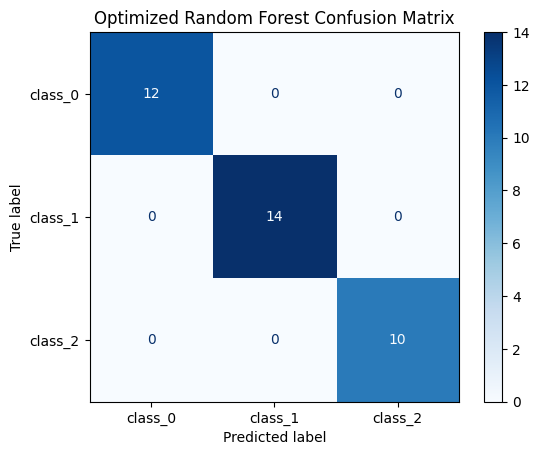

Optimized model saved successfully.
Predicted wine class: class_0


In [5]:
#Common cross-validation strategies
#use StratifiedKFold
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print(cv_strategy)

#visualize how the folds are created

from sklearn.model_selection import cross_validate

rf_baseline = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

cv_scores = cross_val_score(
    rf_baseline,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring="accuracy"
)

print("Fold scores:", cv_scores)
print("Mean accuracy:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())

#Understand GridSearchCV
param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [3, 5, 10]
}


#GridSearchCV implementation
#Define parameter grid
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 3, 5, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

#Create GridSearchCV
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=cv_strategy,
    scoring="accuracy",
    n_jobs=None,
    verbose=1
)

#Execute GridSearchCV
grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest CV accuracy:")
print(grid_search.best_score_)

#Get the optimized model
best_grid_model = grid_search.best_estimator_

print("Optimized model:")
print(best_grid_model)

#RandomizedSearchCV implementation
#Define parameter distributions
param_distributions = {
    "n_estimators": randint(50, 301),
    "max_depth": [None, 3, 5, 10, 15, 20],
    "min_samples_split": randint(2, 11),
    "min_samples_leaf": randint(1, 6),
    "max_features": ["sqrt", "log2", None]
}

#Create RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_distributions,
    n_iter=30,
    cv=cv_strategy,
    scoring="accuracy",
    random_state=42,
    n_jobs=None,
    verbose=1
)

#Execute RandomizedSearchCV
random_search.fit(X_train, y_train)

print("Best parameters:")
print(random_search.best_params_)

print("\nBest CV accuracy:")
print(random_search.best_score_)

#Get the optimized model
best_random_model = random_search.best_estimator_

print(best_random_model)


#Compare both search methods
search_comparison = pd.DataFrame({
    "Search Method": [
        "GridSearchCV",
        "RandomizedSearchCV"
    ],
    "Best CV Accuracy": [
        grid_search.best_score_,
        random_search.best_score_
    ]
})

display(search_comparison)


#Visualize comparison
plt.figure(figsize=(8, 5))

plt.bar(
    search_comparison["Search Method"],
    search_comparison["Best CV Accuracy"]
)

plt.title("GridSearchCV vs RandomizedSearchCV")
plt.xlabel("Search Method")
plt.ylabel("Best CV Accuracy")
plt.ylim(0, 1.05)

plt.show()


#Compare baseline and optimized models
final_models = {
    "Baseline Random Forest": rf_baseline,
    "GridSearchCV Random Forest": best_grid_model,
    "RandomizedSearchCV Random Forest": best_random_model
}

final_results = []

for name, model in final_models.items():
    # Make sure we fit the baseline model as it hasn't been fitted yet
    if name == "Baseline Random Forest":
        model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="weighted"
        ),
        "Recall": recall_score(
            y_test, predictions, average="weighted"
        ),
        "F1 Score": f1_score(
            y_test, predictions, average="weighted"
        )
    })

final_results = pd.DataFrame(final_results)

display(final_results)


#Confusion matrix for the selected model
selected_model = best_grid_model

final_predictions = selected_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    final_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=wine.target_names
)

disp.plot(cmap="Blues")

plt.title("Optimized Random Forest Confusion Matrix")
plt.show()


#Save the optimized model
import joblib

joblib.dump(
    selected_model,
    "optimized_wine_model.pkl"
)

print("Optimized model saved successfully.")

#Load it again
loaded_model = joblib.load("optimized_wine_model.pkl")

prediction = loaded_model.predict(X_test.iloc[[0]])

print("Predicted wine class:", wine.target_names[prediction[0]])


#scale the entire dataset before splitting it into training and testing sets
# Correct approach
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

pipeline.fit(X_train, y_train)

predictions = pipeline.predict(X_test)